### Data Ingestion

we use the langchain that we document structure that is divide :

1 page data 

2 meta data 

3 id 

### Document Structure

In [2]:
from langchain_core.documents import Document

In [4]:
doc = Document(
    page_content="This is a test document.", 
    metadata={
        "source": "test_source",
        "pages": 1,
        "author": "vivek",
        "date_created": "2023-06-01",
        }
        
    )

In [5]:
print(doc)

page_content='This is a test document.' metadata={'source': 'test_source', 'pages': 1, 'author': 'vivek', 'date_created': '2023-06-01'}


In [6]:
print(doc.page_content)
print(doc.metadata)


This is a test document.
{'source': 'test_source', 'pages': 1, 'author': 'vivek', 'date_created': '2023-06-01'}


In [7]:
## make the simple txt file 
import os 
os.makedirs("../data/text_files", exist_ok=True)

In [8]:
sample_texts = {
    "../data/text_files/python_intro.txt": """Python is a high-level, interpreted programming language.
It is known for its simple syntax and readability.
Python is widely used in web development, data science, and machine learning.""",

    "../data/text_files/ml_intro.txt": """Machine learning is a subset of artificial intelligence.
It allows systems to learn from data without being explicitly programmed.
Common types include supervised, unsupervised, and reinforcement learning.""",
}

for path, content in sample_texts.items():
    with open(path, "w", encoding="utf-8") as f:
        f.write(content)

print("Sample text files created!")

Sample text files created!


In [12]:
## read the files
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders import TextLoader
loader = TextLoader("../data/text_files/python_intro.txt")
documents = loader.load()
print(documents)


[Document(metadata={'source': '../data/text_files/python_intro.txt'}, page_content='Python is a high-level, interpreted programming language.\nIt is known for its simple syntax and readability.\nPython is widely used in web development, data science, and machine learning.')]


In [15]:
### if i have the directory loader 
from langchain_community.document_loaders import DirectoryLoader, TextLoader

dir_loader = DirectoryLoader(
    "../data/text_files",
    glob="**/*.txt",
    loader_cls=TextLoader,
    loader_kwargs={"encoding": "utf-8"},
    show_progress=False,
)

documents = dir_loader.load()
print(len(documents))
print(documents[0].metadata)
documents

2
{'source': '..\\data\\text_files\\ml_intro.txt'}


[Document(metadata={'source': '..\\data\\text_files\\ml_intro.txt'}, page_content='Machine learning is a subset of artificial intelligence.\nIt allows systems to learn from data without being explicitly programmed.\nCommon types include supervised, unsupervised, and reinforcement learning.'),
 Document(metadata={'source': '..\\data\\text_files\\python_intro.txt'}, page_content='Python is a high-level, interpreted programming language.\nIt is known for its simple syntax and readability.\nPython is widely used in web development, data science, and machine learning.')]

In [19]:
from langchain_community.document_loaders import DirectoryLoader, PyPDFLoader

pdf_loader = DirectoryLoader(
    "../data/pdf_files",
    glob="**/*.pdf",
    loader_cls=PyPDFLoader,
    show_progress=False,
)

pdf_documents = pdf_loader.load()
print(len(pdf_documents))
pdf_documents

7


[Document(metadata={'producer': 'Skia/PDF m153', 'creator': 'Chromium', 'creationdate': '2026-10-21T08:38:58+00:00', 'title': 'Tokenization from Scratch: Regex to BPE (Medium draft)', 'moddate': '2026-10-21T08:38:58+00:00', 'source': '..\\data\\pdf_files\\Tokenization from Scratch Regex to BPE (Medium draft).pdf', 'total_pages': 7, 'page': 0, 'page_label': '1'}, page_content='Tokenization from Scratch: From a Regex\nSplitter to GPT-2\'s BPE\nPart 1 of my "Building an LLM from Scratch" series\nBefore a language model can learn anything, it has to turn text into numbers. That first\nstage is the tokenizer, and it is where every LLM pipeline begins. In this post I build one\nfrom scratch in Python, hit its limits, and then switch to the same Byte Pair Encoding\n(BPE) approach that GPT-2 and GPT-3 use, through tiktoken .\nI\'m following Build a Large Language Model (From Scratch) by Sebastian Raschka, and this\npost is my own walkthrough of the tokenization chapter.\nThe big picture\nGPT-s

In [20]:
type(pdf_documents[0])

langchain_core.documents.base.Document

In [21]:
type(documents)

list

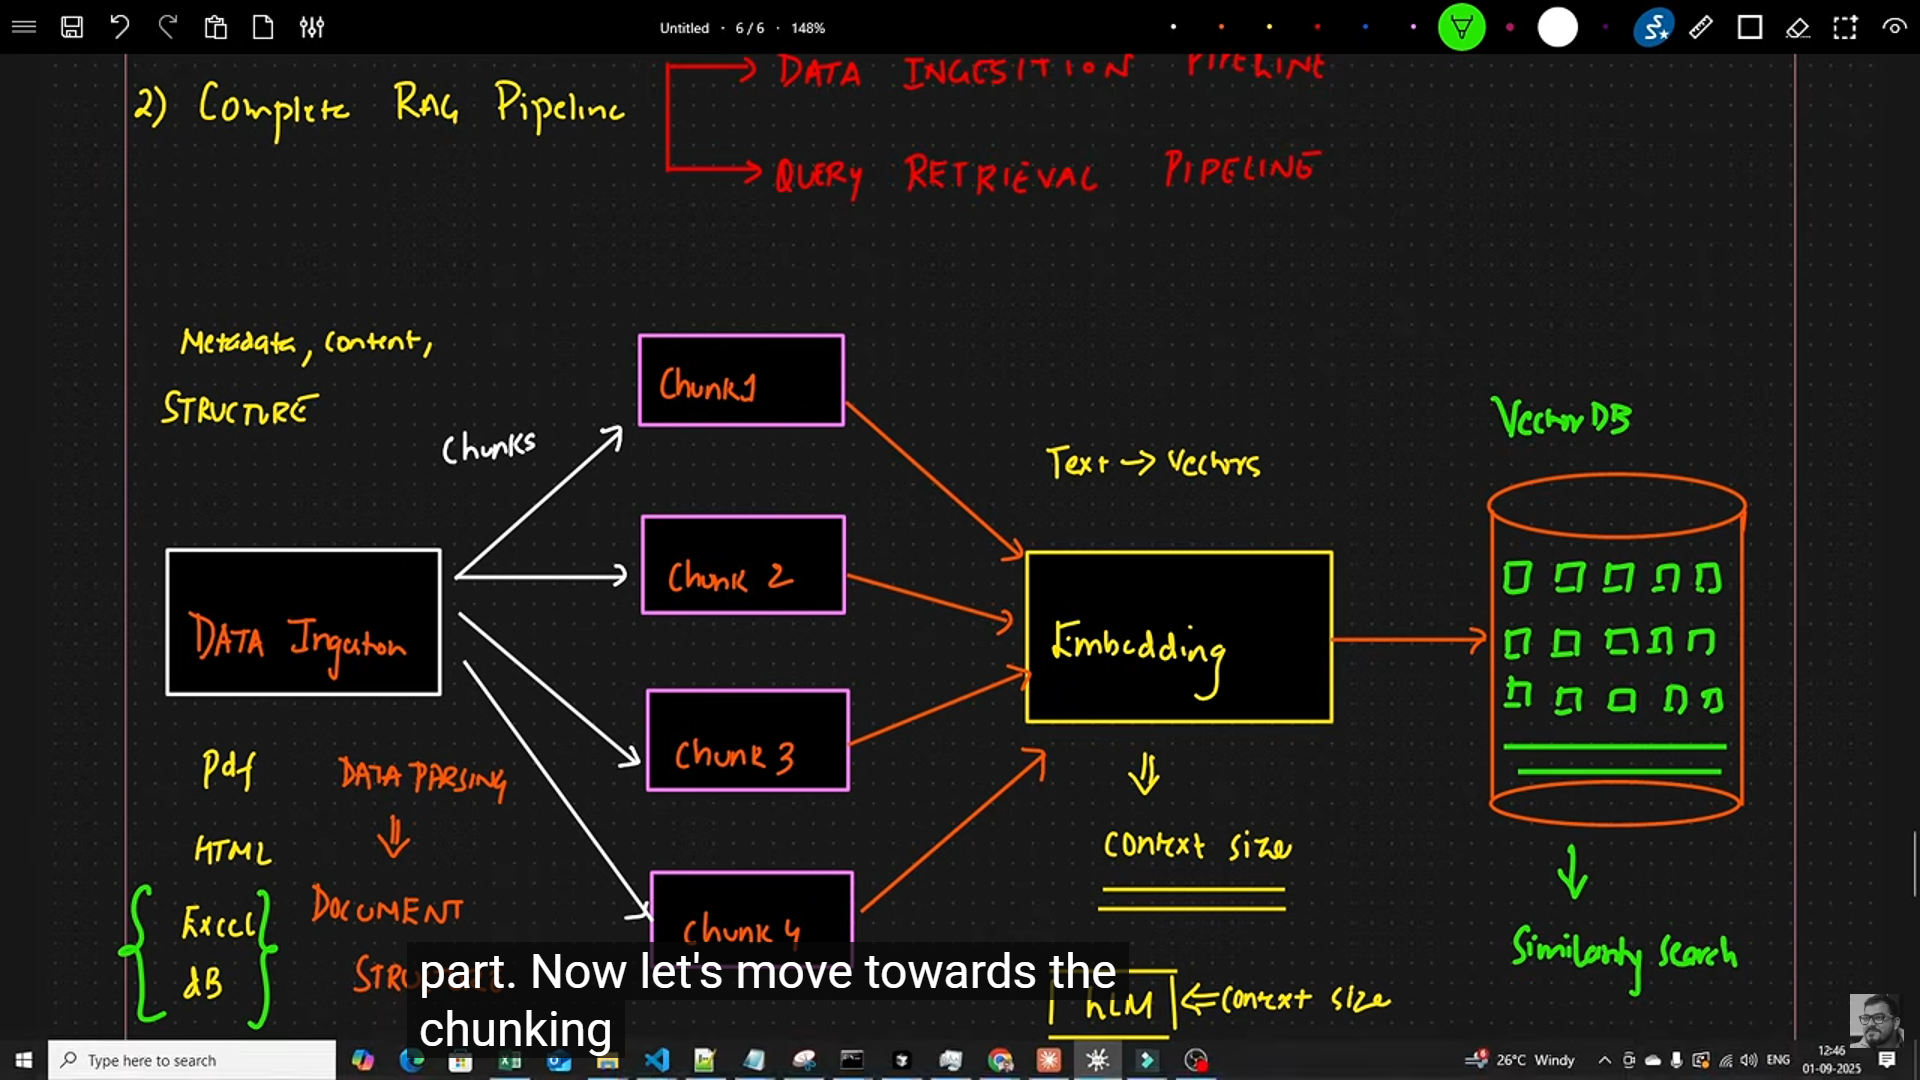

Now the data ingestion that is done.

### Embedding and VectorBase

In [26]:
import numpy as np
from sentence_transformers import SentenceTransformer
import chromadb
from chromadb.config import Settings
import uuid
from typing import List, Dict, Any, Tuple
from sklearn.metrics.pairwise import cosine_similarity

c:\Users\Dell\OneDrive\Documents\Desktop\Rag\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [27]:
## make class constructor for the document 
class EmbeddingManager:
    """Handles document embedding generation using SentenceTransformer"""
    
    def __init__(self, model_name: str = "all-MiniLM-L6-v2"):
        """
        Initialize the embedding manager
        
        Args:
            model_name: HuggingFace model name for sentence embeddings
        """
        self.model_name = model_name
        self.model = None
        self._load_model()

    def _load_model(self):
        """Load the SentenceTransformer model"""
        try:
            print(f"Loading embedding model: {self.model_name}")
            self.model = SentenceTransformer(self.model_name)
            print(f"Model loaded successfully. Embedding dimension: {self.model.get_sentence_embedding_dimension()}")
        except Exception as e:
            print(f"Error loading model {self.model_name}: {e}")
            raise

    def generate_embeddings(self, texts: List[str]) -> np.ndarray:
        """
        Generate embeddings for a list of texts
        
        Args:
            texts: List of text strings to embed
            
        Returns:
            numpy array of embeddings with shape (len(texts), embedding_dim)
        """
        if not self.model:
            raise ValueError("Model not loaded")
        
        print(f"Generating embeddings for {len(texts)} texts...")
        embeddings = self.model.encode(texts, show_progress_bar=True)
        print(f"Generated embeddings with shape: {embeddings.shape}")
        return embeddings


## now we can insilization of embedding manager 
embedding_manager=EmbeddingManager()
embedding_manager        
    

Loading embedding model: all-MiniLM-L6-v2


c:\Users\Dell\OneDrive\Documents\Desktop\Rag\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dell\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Dell\OneDrive\Documents\Desktop\Rag\.venv\Lib\site-packages\huggingface

Model loaded successfully. Embedding dimension: 384


C:\Users\Dell\AppData\Local\Temp\ipykernel_21236\4019495482.py:21: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Model loaded successfully. Embedding dimension: {self.model.get_sentence_embedding_dimension()}")


In [28]:
embedding_manager = EmbeddingManager()

test_embeddings = embedding_manager.generate_embeddings(
    ["Python is a programming language.", "Machine learning is a subset of AI."]
)
print(test_embeddings.shape)  # (2, 384)

Loading embedding model: all-MiniLM-L6-v2


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 108.63it/s]
C:\Users\Dell\AppData\Local\Temp\ipykernel_21236\4019495482.py:21: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Model loaded successfully. Embedding dimension: {self.model.get_sentence_embedding_dimension()}")


Model loaded successfully. Embedding dimension: 384
Generating embeddings for 2 texts...


Batches: 100%|██████████| 1/1 [00:15<00:00, 15.97s/it]


Generated embeddings with shape: (2, 384)
(2, 384)


In [41]:
## lets we do the vactorbase

class VectorStore:
    """Manages document embeddings in a ChromaDB vector store"""
    
    def __init__(self, collection_name: str = "pdf_documents", persist_directory: str = "../data/vector_store"):
        """
        Initialize the vector store
        
        Args:
            collection_name: Name of the ChromaDB collection
            persist_directory: Directory to persist the vector store
        """
        self.collection_name = collection_name
        self.persist_directory = persist_directory
        self.client = None
        self.collection = None
        self._initialize_store()

    def _initialize_store(self):
        """Initialize ChromaDB client and collection"""
        try:
            # Create persistent ChromaDB client
            os.makedirs(self.persist_directory, exist_ok=True)
            self.client = chromadb.PersistentClient(path=self.persist_directory)
            
            # Get or create collection
            self.collection = self.client.get_or_create_collection(
                name=self.collection_name,
                metadata={"description": "PDF document embeddings for RAG"}
            )
            print(f"Vector store initialized. Collection: {self.collection_name}")
            print(f"Existing documents in collection: {self.collection.count()}")
            
        except Exception as e:
            print(f"Error initializing vector store: {e}")
            raise

    def add_documents(self, documents: List[Any], embeddings: np.ndarray):
        """
        Add documents and their embeddings to the vector store
        
        Args:
            documents: List of LangChain documents
            embeddings: Corresponding embeddings for the documents
        """
        if len(documents) != len(embeddings):
            raise ValueError("Number of documents must match number of embeddings")
        
        print(f"Adding {len(documents)} documents to vector store...")
        
        # Prepare data for ChromaDB
        ids = []
        metadatas = []
        documents_text = []
        embeddings_list = []
        
        for i, (doc, embedding) in enumerate(zip(documents, embeddings)):
            # Generate unique ID
            doc_id = f"doc_{uuid.uuid4().hex[:8]}_{i}"
            ids.append(doc_id)
            
            # Prepare metadata
            metadata = dict(doc.metadata)
            metadata['doc_index'] = i
            metadata['content_length'] = len(doc.page_content)
            metadatas.append(metadata)
            
            # Document content
            documents_text.append(doc.page_content)
            
            # Embedding
            embeddings_list.append(embedding.tolist())
        
        # Add to collection
        try:
            self.collection.add(
                ids=ids,
                embeddings=embeddings_list,
                metadatas=metadatas,
                documents=documents_text
            )
            print(f"Successfully added {len(documents)} documents to vector store")
            print(f"Total documents in collection: {self.collection.count()}")
            
        except Exception as e:
            print(f"Error adding documents to vector store: {e}")
            raise

vectorstore=VectorStore()
vectorstore
    

Vector store initialized. Collection: pdf_documents
Existing documents in collection: 0


In [42]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(pdf_documents)

print(len(chunks))
print(chunks[0].page_content[:200])

12
Tokenization from Scratch: From a Regex
Splitter to GPT-2's BPE
Part 1 of my "Building an LLM from Scratch" series
Before a language model can learn anything, it has to turn text into numbers. That fi


In [43]:
chunks

[Document(metadata={'producer': 'Skia/PDF m153', 'creator': 'Chromium', 'creationdate': '2026-10-21T08:38:58+00:00', 'title': 'Tokenization from Scratch: Regex to BPE (Medium draft)', 'moddate': '2026-10-21T08:38:58+00:00', 'source': '..\\data\\pdf_files\\Tokenization from Scratch Regex to BPE (Medium draft).pdf', 'total_pages': 7, 'page': 0, 'page_label': '1'}, page_content='Tokenization from Scratch: From a Regex\nSplitter to GPT-2\'s BPE\nPart 1 of my "Building an LLM from Scratch" series\nBefore a language model can learn anything, it has to turn text into numbers. That first\nstage is the tokenizer, and it is where every LLM pipeline begins. In this post I build one\nfrom scratch in Python, hit its limits, and then switch to the same Byte Pair Encoding\n(BPE) approach that GPT-2 and GPT-3 use, through tiktoken .\nI\'m following Build a Large Language Model (From Scratch) by Sebastian Raschka, and this\npost is my own walkthrough of the tokenization chapter.\nThe big picture\nGPT-s

In [44]:
### Convert the text to embeddings
texts=[doc.page_content for doc in chunks]

## Generate the Embeddings

embeddings=embedding_manager.generate_embeddings(texts)

##store int he vector dtaabase
vectorstore.add_documents(chunks,embeddings)

Generating embeddings for 12 texts...


Batches: 100%|██████████| 1/1 [00:06<00:00,  6.10s/it]


Generated embeddings with shape: (12, 384)
Adding 12 documents to vector store...
Successfully added 12 documents to vector store
Total documents in collection: 12


### Retriever Pipeline From VectorStore

In [45]:
class RAGRetriever:
    """Handles query-based retrieval from the vector store"""
    
    def __init__(self, vector_store: VectorStore, embedding_manager: EmbeddingManager):
        """
        Initialize the retriever
        
        Args:
            vector_store: Vector store containing document embeddings
            embedding_manager: Manager for generating query embeddings
        """
        self.vector_store = vector_store
        self.embedding_manager = embedding_manager

    def retrieve(self, query: str, top_k: int = 5, score_threshold: float = 0.0) -> List[Dict[str, Any]]:
        """
        Retrieve relevant documents for a query
        
        Args:
            query: The search query
            top_k: Number of top results to return
            score_threshold: Minimum similarity score threshold
            
        Returns:
            List of dictionaries containing retrieved documents and metadata
        """
        print(f"Retrieving documents for query: '{query}'")
        print(f"Top K: {top_k}, Score threshold: {score_threshold}")
        
        # Generate query embedding
        query_embedding = self.embedding_manager.generate_embeddings([query])[0]
        
        # Search in vector store
        try:
            results = self.vector_store.collection.query(
                query_embeddings=[query_embedding.tolist()],
                n_results=top_k
            )
            
            # Process results
            retrieved_docs = []
            
            if results['documents'] and results['documents'][0]:
                documents = results['documents'][0]
                metadatas = results['metadatas'][0]
                distances = results['distances'][0]
                ids = results['ids'][0]
                
                for i, (doc_id, document, metadata, distance) in enumerate(zip(ids, documents, metadatas, distances)):
                    # Convert distance to similarity score (ChromaDB uses cosine distance)
                    similarity_score = 1 - distance
                    
                    if similarity_score >= score_threshold:
                        retrieved_docs.append({
                            'id': doc_id,
                            'content': document,
                            'metadata': metadata,
                            'similarity_score': similarity_score,
                            'distance': distance,
                            'rank': i + 1
                        })
                
                print(f"Retrieved {len(retrieved_docs)} documents (after filtering)")
            else:
                print("No documents found")
            
            return retrieved_docs
            
        except Exception as e:
            print(f"Error during retrieval: {e}")
            return []

rag_retriever=RAGRetriever(vectorstore,embedding_manager)

In [46]:
rag_retriever

In [47]:
rag_retriever.retrieve("What is BPE tokenization?")

Retrieving documents for query: 'What is BPE tokenization?'
Top K: 5, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:02<00:00,  2.01s/it]

Generated embeddings with shape: (1, 384)
Retrieved 5 documents (after filtering)


[{'id': 'doc_a88ceb49_10',
  'content': 'A basic tokenizer needs a vocabulary plus encode  and decode .\nRegex word tokenizer BPE (GPT-2)\nUnit Whole words and punctuation Sub-words\nUnknown words Need `< unk\nVocabulary Grows with the data Fixed (50,257 for GPT-2)\nGood for Learning the concept Real models\nTokenization from Scratch: Regex to BPE (Medium draft)\nPage 6 of 7',
  'metadata': {'title': 'Tokenization from Scratch: Regex to BPE (Medium draft)',
   'producer': 'Skia/PDF m153',
   'page_label': '6',
   'source': '..\\data\\pdf_files\\Tokenization from Scratch Regex to BPE (Medium draft).pdf',
   'total_pages': 7,
   'moddate': '2026-10-21T08:38:58+00:00',
   'doc_index': 10,
   'content_length': 329,
   'creator': 'Chromium',
   'page': 5,
   'creationdate': '2026-10-21T08:38:58+00:00'},
  'similarity_score': 0.5020496845245361,
  'distance': 0.49795031547546387,
  'rank': 1},
 {'id': 'doc_78251342_0',
  'content': 'Tokenization from Scratch: From a Regex\nSplitter to GPT-2\

In [48]:
rag_retriever.retrieve("Why do we need special tokens like <|unk|>?")

Retrieving documents for query: 'Why do we need special tokens like <|unk|>?'
Top K: 5, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:04<00:00,  4.03s/it]

Generated embeddings with shape: (1, 384)
Retrieved 5 documents (after filtering)


[{'id': 'doc_65dc5127_6',
  'content': 'all_tokens = sorted(list(set(clean_text)))\nall_tokens.extend(["<|endoftext|>", "<|unk|>"])\nvocab = {token: integer for integer, token in enumerate(all_tokens)}\nprint(len(vocab))   # 1132\n(Small bug to watch for: in my first notebook I typed "<|unk|"  without the closing > . The\ntoken in the vocab must exactly match the one used in encode , otherwise you get another\nKeyError.)\nNow update encode  to fall back to <|unk|> :\nTokenization from Scratch: Regex to BPE (Medium draft)\nPage 4 of 7',
  'metadata': {'page': 3,
   'total_pages': 7,
   'doc_index': 6,
   'content_length': 490,
   'moddate': '2026-10-21T08:38:58+00:00',
   'title': 'Tokenization from Scratch: Regex to BPE (Medium draft)',
   'producer': 'Skia/PDF m153',
   'source': '..\\data\\pdf_files\\Tokenization from Scratch Regex to BPE (Medium draft).pdf',
   'creator': 'Chromium',
   'creationdate': '2026-10-21T08:38:58+00:00',
   'page_label': '4'},
  'similarity_score': 0.58280

### RAG Pipeline- VectorDB To LLM Output Generation

In [50]:
%pip install groq

Note: you may need to restart the kernel to use updated packages.


c:\Users\Dell\OneDrive\Documents\Desktop\Rag\.venv\Scripts\python.exe: No module named pip


In [55]:
%pip install groq python-dotenv

Note: you may need to restart the kernel to use updated packages.


c:\Users\Dell\OneDrive\Documents\Desktop\Rag\.venv\Scripts\python.exe: No module named pip


In [56]:
import os
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv())

print(os.getenv("GROQ_API_KEY") is not None)  # True aana chahiye

True


In [58]:
import os
from dotenv import load_dotenv, find_dotenv
from groq import Groq

load_dotenv(find_dotenv())
client = Groq(api_key=os.getenv("GROQ_API_KEY"))

In [62]:

from langchain_core.prompts import PromptTemplate
from langchain_core.messages import HumanMessage, SystemMessage

In [63]:
import os
from groq import Groq


class GroqLLM:
    def __init__(self, model_name: str = "llama-3.3-70b-versatile", api_key: str = None):
        self.model_name = model_name
        self.api_key = api_key or os.environ.get("GROQ_API_KEY")

        if not self.api_key:
            raise ValueError("Groq API key required. Set GROQ_API_KEY in .env or pass api_key.")

        self.client = Groq(api_key=self.api_key)
        print(f"Initialized Groq LLM with model: {self.model_name}")

    def generate_response(self, query: str, context: str, max_tokens: int = 500) -> str:
        prompt = f"""You are a helpful AI assistant. Use the following context to answer the question accurately and concisely.

Context:
{context}

Question: {query}

Answer: Provide a clear and informative answer based on the context above. If the context doesn't contain enough information to answer the question, say so."""

        try:
            response = self.client.chat.completions.create(
                model=self.model_name,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.1,
                max_tokens=max_tokens,
            )
            return response.choices[0].message.content
        except Exception as e:
            return f"Error generating response: {e}"


# usage
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv())

groq_llm = GroqLLM()

query = "What is BPE tokenization?"
results = rag_retriever.retrieve(query, top_k=3, score_threshold=0.3)
context = "\n\n".join(r["content"] for r in results)

print(groq_llm.generate_response(query, context))

Initialized Groq LLM with model: llama-3.3-70b-versatile
Retrieving documents for query: 'What is BPE tokenization?'
Top K: 3, Score threshold: 0.3
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:02<00:00,  2.25s/it]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
Error generating response: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}


In [65]:
models = groq_llm.client.models.list()
for m in models.data:
    print(m.id)

qwen/qwen3.8-27b
openai/gpt-oss-safeguard-20b
whisper-large-v3-turbo
openai/gpt-oss-120b
openai/gpt-oss-20b
canopylabs/orpheus-v1-english
canopylabs/orpheus-arabic-saudi
meta-llama/llama-prompt-guard-2-86m
meta-llama/llama-prompt-guard-2-22m
allam-2-7b
whisper-large-v3


In [64]:
# Initialize Groq LLM (you'll need to set GROQ_API_KEY environment variable)
try:
    groq_llm = GroqLLM(api_key=os.getenv("GROQ_API_KEY"))
    print("Groq LLM initialized successfully!")
except ValueError as e:
    print(f"Warning: {e}")
    print("Please set your GROQ_API_KEY environment variable to use the LLM.")
    groq_llm = None

Initialized Groq LLM with model: llama-3.3-70b-versatile
Groq LLM initialized successfully!


In [66]:
def ask(query: str, top_k: int = 3, score_threshold: float = 0.3) -> str:
    results = rag_retriever.retrieve(query, top_k=top_k, score_threshold=score_threshold)
    if not results:
        return "No relevant context found."
    context = "\n\n".join(r["content"] for r in results)
    return groq_llm.generate_response(query, context, max_tokens=1024)


print(ask("What is BPE tokenization?"))
print(ask("Why do we need special tokens like <|unk|>?"))
print(ask("What is the vocabulary size of GPT-2?"))

Retrieving documents for query: 'What is BPE tokenization?'
Top K: 3, Score threshold: 0.3
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:05<00:00,  5.78s/it]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
Error generating response: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}
Retrieving documents for query: 'Why do we need special tokens like <|unk|>?'
Top K: 3, Score threshold: 0.3
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:02<00:00,  2.51s/it]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
Error generating response: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}
Retrieving documents for query: 'What is the vocabulary size of GPT-2?'
Top K: 3, Score threshold: 0.3
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:03<00:00,  3.45s/it]

Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
Error generating response: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}


In [67]:
groq_llm = GroqLLM(model_name="openai/gpt-oss-20b")
print(groq_llm.model_name)  # openai/gpt-oss-20b aana chahiye

print(ask("What is BPE tokenization?"))

Initialized Groq LLM with model: openai/gpt-oss-20b
openai/gpt-oss-20b
Retrieving documents for query: 'What is BPE tokenization?'
Top K: 3, Score threshold: 0.3
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:00<00:00,  1.07it/s]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
**BPE tokenization** (Byte‑Pair Encoding tokenization) is a method for converting raw text into a sequence of sub‑word tokens that a language model can process.  

Key points from the context:

- **Sub‑word units**: Instead of treating whole words as single tokens, BPE splits words into smaller pieces (sub‑words) so that even rare or unseen words can be represented by a combination of known sub‑words.
- **Avoids unknown‑word problem**: Because every word can be broken down into sub‑words, the tokenizer rarely needs a special `<unk>` token.  
- **Vocabulary size**: GPT‑2 uses a fixed vocabulary of 50,257 tokens, built by iteratively merging the most frequent byte‑pair combinations in the training data.
- **Pipeline role**: In a decoder‑only transformer (like GPT‑2/3), the tokenizer is the first step that turns raw text → tokens → token IDs → embeddings → model.

In short, BPE tokenization is a data‑driven,

In [68]:
### get the context from the retriever and pass it to the LLM

rag_retriever.retrieve("What is BPE tokenization?")

Retrieving documents for query: 'What is BPE tokenization?'
Top K: 5, Score threshold: 0.0
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:02<00:00,  2.37s/it]


Generated embeddings with shape: (1, 384)
Retrieved 5 documents (after filtering)


[{'id': 'doc_a88ceb49_10',
  'content': 'A basic tokenizer needs a vocabulary plus encode  and decode .\nRegex word tokenizer BPE (GPT-2)\nUnit Whole words and punctuation Sub-words\nUnknown words Need `< unk\nVocabulary Grows with the data Fixed (50,257 for GPT-2)\nGood for Learning the concept Real models\nTokenization from Scratch: Regex to BPE (Medium draft)\nPage 6 of 7',
  'metadata': {'page_label': '6',
   'creator': 'Chromium',
   'moddate': '2026-10-21T08:38:58+00:00',
   'source': '..\\data\\pdf_files\\Tokenization from Scratch Regex to BPE (Medium draft).pdf',
   'creationdate': '2026-10-21T08:38:58+00:00',
   'page': 5,
   'content_length': 329,
   'producer': 'Skia/PDF m153',
   'doc_index': 10,
   'total_pages': 7,
   'title': 'Tokenization from Scratch: Regex to BPE (Medium draft)'},
  'similarity_score': 0.5020496845245361,
  'distance': 0.49795031547546387,
  'rank': 1},
 {'id': 'doc_78251342_0',
  'content': 'Tokenization from Scratch: From a Regex\nSplitter to GPT-2\

In [69]:
def rag_simple(query, retriever, llm, top_k=3, score_threshold=0.3):
    results = retriever.retrieve(query, top_k=top_k, score_threshold=score_threshold)
    context = "\n\n".join(doc["content"] for doc in results) if results else ""
    if not context:
        return "No relevant context found to answer the question."

    prompt = f"""Use ONLY the following context to answer the question concisely.
If the answer is not in the context, say "I don't know based on the provided documents."

Context:
{context}

Question: {query}

Answer:"""

    response = llm.client.chat.completions.create(
        model=llm.model_name,
        messages=[{"role": "user", "content": prompt}],
        temperature=0.1,
        max_tokens=1024,
    )
    return response.choices[0].message.content


print(rag_simple("What is BPE tokenization?", rag_retriever, groq_llm))

Retrieving documents for query: 'What is BPE tokenization?'
Top K: 3, Score threshold: 0.3
Generating embeddings for 1 texts...


Batches: 100%|██████████| 1/1 [00:01<00:00,  1.63s/it]


Generated embeddings with shape: (1, 384)
Retrieved 3 documents (after filtering)
BPE tokenization is a sub‑word method that builds a fixed vocabulary by repeatedly merging the most frequent pairs of bytes (or characters) in a corpus. It is used by GPT‑2/3 to avoid unknown‑word problems, turning text into tokens that can be encoded into integer IDs for the model.
